In [1]:
# Install the two extra packages, matched to the TensorFlow version Colab already has
import tensorflow as tf
TFV = ".".join(tf.__version__.split(".")[:2])
print("Colab TensorFlow:", tf.__version__)
!pip install -q "tf-keras=={TFV}.*" keras-cv-attention-models
!pip show tf-keras keras-cv-attention-models | grep -E "^(Name|Version)"
print("\nNow: Runtime -> Restart session, then continue from the SETUP cell.")

Colab TensorFlow: 2.21.0
Name: tf_keras
Version: 2.21.0
Name: keras-cv-attention-models
Version: 1.4.3

Now: Runtime -> Restart session, then continue from the SETUP cell.


In [1]:
# ============================== SETUP ==============================
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"          # must be set before importing TensorFlow
import json, random, glob
import numpy as np, pandas as pd, tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, multilabel_confusion_matrix)
layers = tf.keras.layers
Model = tf.keras.Model
assert "tf_keras" in tf.keras.__file__, "Legacy Keras not active: Runtime -> Restart session, then run this cell first."
assert tf.config.list_physical_devices("GPU"), "Switch the runtime to a T4 GPU."
from google.colab import drive
drive.mount('/content/drive')

DATA_ROOT = "/content/drive/MyDrive/acne clean pigmentation wrinkles"
SAVE_DIR  = os.path.join(DATA_ROOT, "multistage_camera_ready"); os.makedirs(SAVE_DIR, exist_ok=True)
ASSISTANT_WEIGHTS_PATH = os.path.join(DATA_ROOT, "maxvit_tiny_skin_model_FINAL_TUNED.weights.h5")
TEACHER_TRAIN_PROBS    = os.path.join(DATA_ROOT, "teacher_train_probs.npy")
KAGGLE_MAXVIT_TEST     = os.path.join(DATA_ROOT, "maxvit_preds.npy")   # optional, to identify the assistant

CLASSES = ["acne", "pigmentation", "wrinkles"]; NUM_CLASSES = 3
IMG_SIZE = (224, 224); IMG_HEIGHT, IMG_WIDTH = IMG_SIZE; IMG_CHANNELS = 3
BATCH_SIZE = 32
# Stage 2 / student settings - identical to the original multi-stage RKD notebook
LEARNING_RATE = 1e-4; EPOCHS_STUDENT = 15; TEMPERATURE = 3.0
ALPHA_SUP, ALPHA_KD, ALPHA_RKD = 1.0, 0.2, 0.2
RKD_DISTANCE_WEIGHT, RKD_ANGLE_WEIGHT = 1.0, 2.0
# Stage 1 settings (ensemble -> MaxViT)
STAGE1_EPOCHS, STAGE1_LR, STAGE1_BATCH, STAGE1_ALPHA_KD = 5, 1e-5, 8, 1.0

def set_seeds(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed); random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
print("TF", tf.__version__, "| SAVE_DIR:", SAVE_DIR)

Mounted at /content/drive
TF 2.21.0 | SAVE_DIR: /content/drive/MyDrive/acne clean pigmentation wrinkles/multistage_camera_ready


In [2]:
# ============================== DATA ==============================
df = pd.read_csv(os.path.join(DATA_ROOT, "labels.csv"))
df["filename"] = df["filename"].astype(str).apply(lambda x: os.path.join(DATA_ROOT, x))
# Same split code as the notebook that produced teacher_train_probs.npy (keeps row order aligned)
train_val_df, test_df = train_test_split(df, test_size=0.15, random_state=42, stratify=df[CLASSES])
train_df, val_df = train_test_split(train_val_df, test_size=0.15, random_state=42, stratify=train_val_df[CLASSES])
print("Train/Val/Test:", len(train_df), len(val_df), len(test_df))
assert (len(train_df), len(val_df), len(test_df)) == (3656, 646, 760)
assert list(train_df[CLASSES].sum().astype(int)) == [1015, 386, 738]

pos = train_df[CLASSES].sum().values.astype(np.float32)
POS_WEIGHT = tf.constant((len(train_df) - pos) / (pos + 1e-8), dtype=tf.float32)

T_ENS = np.load(TEACHER_TRAIN_PROBS).astype(np.float32)
assert T_ENS.shape == (len(train_df), 3)
agree = ((T_ENS > 0.5).astype(int) == train_df[CLASSES].values.astype(int)).mean()
print(f"Ensemble soft labels vs training labels, per-label agreement: {agree:.4f}")
assert agree > 0.97, "teacher_train_probs.npy is not aligned with this training split - stop and report."

augment = tf.keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.05),
                               layers.RandomZoom(0.1)], name="data_augmentation")
def load_img(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(tf.image.convert_image_dtype(img, tf.float32), IMG_SIZE)
    img.set_shape([*IMG_SIZE, 3]); return img

def make_ds(frame, soft=None, batch=BATCH_SIZE, train=False):
    soft = np.zeros((len(frame), 3), np.float32) if soft is None else soft
    ds = tf.data.Dataset.from_tensor_slices((frame["filename"].values, soft, frame[CLASSES].values.astype(np.float32)))
    if train: ds = ds.shuffle(len(frame), seed=42, reshuffle_each_iteration=True)
    ds = ds.map(lambda f, t, y: ((load_img(f), t), y), num_parallel_calls=tf.data.AUTOTUNE)
    if train: ds = ds.map(lambda xt, y: ((augment(xt[0], training=True), xt[1]), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_df, T_ENS, train=True)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)            # fixed order -> saved predictions line up with test_df
Y_TEST = test_df[CLASSES].values.astype(int)
test_df[["filename"] + CLASSES].to_csv(os.path.join(SAVE_DIR, "test_split.csv"), index=False)
print("Datasets ready.")

Train/Val/Test: 3656 646 760
Ensemble soft labels vs training labels, per-label agreement: 0.9995
Datasets ready.


In [3]:
# ============================== LOSSES (from the original notebook) ==============================
# ================================
# RKD LOSSES
# ================================
def pdist_euclidean(embeddings, squared=False, eps=1e-12):
    dot_product = tf.matmul(embeddings, embeddings, transpose_b=True)
    square_norm = tf.linalg.diag_part(dot_product)

    distances = (
        tf.expand_dims(square_norm, 1)
        - 2.0 * dot_product
        + tf.expand_dims(square_norm, 0)
    )
    distances = tf.maximum(distances, 0.0)

    if not squared:
        mask = tf.cast(tf.equal(distances, 0.0), tf.float32)
        distances = distances + mask * eps
        distances = tf.sqrt(distances)
        distances = distances * (1.0 - mask)

    return distances

def rkd_distance_loss(teacher_emb, student_emb, eps=1e-12):
    t_d = pdist_euclidean(teacher_emb, squared=False)
    s_d = pdist_euclidean(student_emb, squared=False)

    t_nonzero = tf.boolean_mask(t_d, t_d > 0)
    s_nonzero = tf.boolean_mask(s_d, s_d > 0)

    t_mean = tf.cond(
        tf.size(t_nonzero) > 0,
        lambda: tf.reduce_mean(t_nonzero),
        lambda: tf.constant(1.0, dtype=t_d.dtype)
    )

    s_mean = tf.cond(
        tf.size(s_nonzero) > 0,
        lambda: tf.reduce_mean(s_nonzero),
        lambda: tf.constant(1.0, dtype=s_d.dtype)
    )

    t_d = t_d / (t_mean + eps)
    s_d = s_d / (s_mean + eps)

    return tf.reduce_mean(tf.abs(t_d - s_d))

def pairwise_difference(embeddings):
    return tf.expand_dims(embeddings, 0) - tf.expand_dims(embeddings, 1)

def normalize_vectors(x, eps=1e-12):
    norm = tf.norm(x, axis=-1, keepdims=True)
    return x / (norm + eps)

def rkd_angle_loss(teacher_emb, student_emb, eps=1e-12):
    t_diff = pairwise_difference(teacher_emb)
    s_diff = pairwise_difference(student_emb)

    t_norm = normalize_vectors(t_diff, eps)
    s_norm = normalize_vectors(s_diff, eps)

    t_angle = tf.matmul(t_norm, t_norm, transpose_b=True)
    s_angle = tf.matmul(s_norm, s_norm, transpose_b=True)

    return tf.reduce_mean(tf.abs(t_angle - s_angle))

def rkd_total_loss(teacher_emb, student_emb, distance_weight=1.0, angle_weight=2.0):
    d_loss = rkd_distance_loss(teacher_emb, student_emb)
    a_loss = rkd_angle_loss(teacher_emb, student_emb)
    return distance_weight * d_loss + angle_weight * a_loss

# ================================
# BCE + KD
# ================================
def weighted_bce_from_logits(y_true, logits, pos_weight=None):
    y_true = tf.cast(y_true, tf.float32)

    if pos_weight is None:
        loss = tf.nn.sigmoid_cross_entropy_with_logits(labels=y_true, logits=logits)
    else:
        pos_weight = tf.cast(pos_weight, tf.float32)
        loss = tf.nn.weighted_cross_entropy_with_logits(
            labels=y_true,
            logits=logits,
            pos_weight=pos_weight
        )

    return tf.reduce_mean(loss)

def multilabel_kd_loss(teacher_logits, student_logits, temperature=3.0):
    teacher_soft = tf.sigmoid(teacher_logits / temperature)
    student_soft = tf.sigmoid(student_logits / temperature)

    kd = tf.keras.losses.binary_crossentropy(teacher_soft, student_soft)
    kd = tf.reduce_mean(kd)

    return kd * (temperature ** 2)

In [4]:
# ============================== STUDENT (from the original notebook) ==============================
# ============================================================
# 5) MobileViT Student (KD-compatible, no dynamic layer creation)
# ============================================================
import tensorflow as tf
from tensorflow.keras import layers, Model

class ConvBNAct(layers.Layer):
    def __init__(self, filters, kernel=3, stride=1, act=True, name_prefix="cba"):
        super().__init__(name=name_prefix)
        self.conv = layers.Conv2D(filters, kernel, stride, padding="same", use_bias=False)
        self.bn = layers.BatchNormalization()
        self.act = layers.Activation("swish") if act else None

    def call(self, x, training=False):
        x = self.conv(x)
        x = self.bn(x, training=training)
        if self.act is not None:
            x = self.act(x)
        return x

class InvertedResidual(layers.Layer):
    def __init__(self, out_ch, stride=1, expand_ratio=4, name_prefix="ir"):
        super().__init__(name=name_prefix)
        self.out_ch = out_ch
        self.stride = stride
        self.expand_ratio = expand_ratio
        self.expand = None  # created in build when in_ch known
        self.dw = layers.DepthwiseConv2D(3, stride, padding="same", use_bias=False)
        self.dw_bn = layers.BatchNormalization()
        self.dw_act = layers.Activation("swish")
        self.proj = layers.Conv2D(out_ch, 1, 1, padding="same", use_bias=False)
        self.proj_bn = layers.BatchNormalization()

    def build(self, input_shape):
        in_ch = int(input_shape[-1])
        hidden = int(in_ch * self.expand_ratio)
        if self.expand_ratio != 1:
            self.expand = ConvBNAct(hidden, kernel=1, stride=1, act=True, name_prefix=self.name + "_expand")
        self.use_res = (self.stride == 1 and in_ch == self.out_ch)
        super().build(input_shape)

    def call(self, x, training=False):
        shortcut = x
        if self.expand is not None:
            x = self.expand(x, training=training)

        x = self.dw(x)
        x = self.dw_bn(x, training=training)
        x = self.dw_act(x)

        x = self.proj(x)
        x = self.proj_bn(x, training=training)

        if self.use_res:
            x = layers.add([shortcut, x])
        return x

class MobileViTBlock(layers.Layer):
    def __init__(self, dim, depth=2, patch_size=(2,2), num_heads=4, name_prefix="mvit"):
        super().__init__(name=name_prefix)
        self.dim = dim
        self.depth = depth
        self.ph, self.pw = patch_size
        self.num_heads = num_heads

        # Local convs
        self.local1 = ConvBNAct(dim, kernel=1, stride=1, act=True, name_prefix=self.name + "_local1")
        self.local2 = ConvBNAct(dim, kernel=3, stride=1, act=True, name_prefix=self.name + "_local2")

        # Token projection
        self.tok_proj = layers.Dense(dim)

        # Transformer blocks
        self.ln1 = [layers.LayerNormalization(epsilon=1e-6) for _ in range(depth)]
        self.mha = [layers.MultiHeadAttention(num_heads=num_heads, key_dim=max(1, dim // num_heads)) for _ in range(depth)]
        self.ln2 = [layers.LayerNormalization(epsilon=1e-6) for _ in range(depth)]
        self.ffn1 = [layers.Dense(dim*2, activation="swish") for _ in range(depth)]
        self.ffn2 = [layers.Dense(dim) for _ in range(depth)]

        # Unprojection back to patches
        self.tok_unproj = layers.Dense(self.ph * self.pw * dim)

        # Fusion
        self.fuse = ConvBNAct(dim, kernel=3, stride=1, act=True, name_prefix=self.name + "_fuse")

    def call(self, x, training=False):
        # Local reps
        x_local = self.local1(x, training=training)
        x_local = self.local2(x_local, training=training)

        # Extract patches: (B, H/ph, W/pw, ph*pw*dim)
        patches = tf.image.extract_patches(
            images=x_local,
            sizes=[1, self.ph, self.pw, 1],
            strides=[1, self.ph, self.pw, 1],
            rates=[1, 1, 1, 1],
            padding="VALID"
        )

        b = tf.shape(patches)[0]
        hh = tf.shape(patches)[1]
        ww = tf.shape(patches)[2]

        # Flatten to tokens: (B, N, ph*pw*dim)
        patches = tf.reshape(patches, [b, hh * ww, self.ph * self.pw * self.dim])

        tokens = self.tok_proj(patches)

        # Transformer encoder
        for i in range(self.depth):
            y = self.ln1[i](tokens)
            y = self.mha[i](y, y, training=training)
            tokens = tokens + y

            y = self.ln2[i](tokens)
            y = self.ffn1[i](y)
            y = self.ffn2[i](y)
            tokens = tokens + y

        # Unproject: (B, N, ph*pw*dim)
        tokens = self.tok_unproj(tokens)

        # Fold back to feature map: (B, hh*ph, ww*pw, dim)
        tokens = tf.reshape(tokens, [b, hh, ww, self.ph, self.pw, self.dim])
        tokens = tf.transpose(tokens, [0, 1, 3, 2, 4, 5])
        x_global = tf.reshape(tokens, [b, hh * self.ph, ww * self.pw, self.dim])

        # Resize back to x_local spatial dims
        x_global = tf.image.resize(x_global, tf.shape(x_local)[1:3])

        # Fuse with original x
        x_fuse = tf.concat([x, x_global], axis=-1)
        x_fuse = self.fuse(x_fuse, training=training)
        return x_fuse

class KDStudentMobileViT(Model):
    """
    KD-ready student:
    - outputs logits (no sigmoid)
    - deep feature map accessible for multi-stage KD
    """
    def __init__(self, num_classes=3, width=1.0, img_size=(224,224), name="mobilevit_student"):
        super().__init__(name=name)
        self.num_classes = num_classes
        self.width = width
        self.img_size = img_size

        self.stem_conv = layers.Conv2D(int(16*width), 3, 2, padding="same", use_bias=False)
        self.stem_bn = layers.BatchNormalization()
        self.stem_act = layers.Activation("swish")

        self.b1 = InvertedResidual(int(16*width), stride=1, expand_ratio=2, name_prefix="b1")
        self.b2 = InvertedResidual(int(24*width), stride=2, expand_ratio=2, name_prefix="b2")
        self.b3 = InvertedResidual(int(24*width), stride=1, expand_ratio=2, name_prefix="b3")

        self.m1_pre = InvertedResidual(int(48*width), stride=2, expand_ratio=4, name_prefix="m1_pre")
        self.m1 = MobileViTBlock(dim=int(64*width), depth=2, patch_size=(2,2), name_prefix="mvit1")

        self.m2_pre = InvertedResidual(int(64*width), stride=2, expand_ratio=4, name_prefix="m2_pre")
        self.m2 = MobileViTBlock(dim=int(80*width), depth=2, patch_size=(2,2), name_prefix="mvit2")

        self.m3_pre = InvertedResidual(int(80*width), stride=2, expand_ratio=4, name_prefix="m3_pre")
        self.m3 = MobileViTBlock(dim=int(96*width), depth=2, patch_size=(2,2), name_prefix="mvit3")

        self.head = ConvBNAct(int(128*width), kernel=1, stride=1, act=True, name_prefix="head")

        self.gap = layers.GlobalAveragePooling2D()
        self.drop = layers.Dropout(0.2)
        self.logits = layers.Dense(num_classes, activation=None, name="logits")  # logits

    def call(self, x, training=False, return_features=False):
        x = self.stem_conv(x)
        x = self.stem_bn(x, training=training)
        x = self.stem_act(x)

        x = self.b1(x, training=training)
        x = self.b2(x, training=training)
        x = self.b3(x, training=training)

        x = self.m1_pre(x, training=training)
        x = self.m1(x, training=training)

        x = self.m2_pre(x, training=training)
        x = self.m2(x, training=training)

        x = self.m3_pre(x, training=training)
        x = self.m3(x, training=training)

        x = self.head(x, training=training)
        deep_features = x  # for multi-stage KD later

        x = self.gap(x)
        x = self.drop(x, training=training)
        out_logits = self.logits(x)

        if return_features:
            return out_logits, deep_features
        return out_logits


class StudentWithEmbedding(tf.keras.Model):
    def __init__(self, student_core):
        super().__init__(name="StudentWithEmbedding")
        self.student_core = student_core
        self.gap = tf.keras.layers.GlobalAveragePooling2D(name="student_embedding_gap")

    def call(self, x, training=False):
        logits, deep_features = self.student_core(
            x, training=training, return_features=True
        )
        embedding = self.gap(deep_features)
        return logits, embedding

In [5]:
# ============================== ASSISTANT (MaxViT, from the original notebook) ==============================
from keras_cv_attention_models import maxvit

IMG_SIZE = (224, 224)
CLASSES = ["acne", "pigmentation", "wrinkles"]

def build_maxvit_for_loading(dropout_rate=0.3):
    inputs = layers.Input(shape=IMG_SIZE + (3,), dtype="float32")

    base_model = maxvit.MaxViT_Tiny(
        input_shape=IMG_SIZE + (3,),
        pretrained="imagenet",
        num_classes=0
    )

    x = base_model(inputs)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(len(CLASSES), activation="sigmoid", dtype="float32")(x)

    model = Model(inputs, outputs, name="maxvit_tiny_hyper_model")
    return model

class LoadedAssistantWrapper(tf.keras.Model):
    def __init__(self, loaded_model):
        super().__init__(name="LoadedAssistantWrapper")
        self.loaded_model = loaded_model

        # Penultimate layer as embedding source
        self.feature_extractor = tf.keras.Model(
            inputs=loaded_model.input,
            outputs=loaded_model.layers[-2].output
        )

    def call(self, x, training=False):
        embedding = self.feature_extractor(x, training=training)
        probs = self.loaded_model(x, training=training)

        probs = tf.clip_by_value(probs, 1e-6, 1.0 - 1e-6)
        logits = tf.math.log(probs / (1.0 - probs))

        return logits, embedding

def load_assistant(weights_path):
    m = build_maxvit_for_loading(dropout_rate=0.3)
    _ = m(tf.zeros((1, *IMG_SIZE, 3)), training=False)
    m.load_weights(weights_path)
    return m

In [6]:
# ============================== EVALUATION HELPERS ==============================
def metrics(y, p, name):
    yp = (p >= 0.5).astype(int)
    r = {"name": name, "exact_match_acc": accuracy_score(y, yp), "per_label_acc": float((y == yp).mean())}
    for avg in ["macro", "micro"]:
        P, R, F, _ = precision_recall_fscore_support(y, yp, average=avg, zero_division=0)
        r.update({f"{avg}_P": P, f"{avg}_R": R, f"{avg}_F1": F, f"{avg}_AUC": roc_auc_score(y, p, average=avg)})
    P, R, F, _ = precision_recall_fscore_support(y, yp, average=None, zero_division=0)
    r["per_class_F1"] = dict(zip(CLASSES, F.round(4).tolist()))
    r["per_class_recall"] = dict(zip(CLASSES, R.round(4).tolist()))
    r["confusion [[TN,FP],[FN,TP]]"] = {c: m.tolist() for c, m in zip(CLASSES, multilabel_confusion_matrix(y, yp))}
    return r

def predict_student(student):
    return np.concatenate([tf.sigmoid(student(x[0], training=False)[0]).numpy() for x, _ in test_ds])
def predict_assistant(m):
    return np.concatenate([m(x[0], training=False).numpy() for x, _ in test_ds])

def save_result(tag, probs, extra=None):
    r = metrics(Y_TEST, probs, tag); r.update(extra or {})
    np.save(os.path.join(SAVE_DIR, f"{tag}_test_probs.npy"), probs)
    with open(os.path.join(SAVE_DIR, f"{tag}_metrics.json"), "w") as f: json.dump(r, f, indent=2, default=float)
    print(json.dumps(r, indent=2, default=float)); return r
def done(tag): return os.path.exists(os.path.join(SAVE_DIR, f"{tag}_metrics.json"))

In [7]:
# ============================== WHICH MaxViT IS THE ASSISTANT? ==============================
assistant = load_assistant(ASSISTANT_WEIGHTS_PATH)
p_assist = predict_assistant(assistant)
if not done("assistant_original"):
    save_result("assistant_original", p_assist)
if os.path.exists(KAGGLE_MAXVIT_TEST):
    pk = np.load(KAGGLE_MAXVIT_TEST)
    print(f"\nMax |difference| vs maxvit_preds.npy (MaxViT used in the ensemble): {np.abs(pk - p_assist).max():.4f}")
    print("-> ~0 means the assistant IS the ensemble's MaxViT; large means it is the other (Colab) MaxViT.")

126113280/126113280 [==============================] - 3s 0us/step
>>>> Load pretrained from: /root/.keras/models/maxvit_tiny_224_imagenet.h5


In [8]:
# ============================== STUDENT TRAINER (runs A-D) ==============================
class StudentTrainer(tf.keras.Model):
    """mode: 'none' (labels only), 'ens_kd' (KD from ensemble soft labels), 'assist_rkd' (KD+RKD from MaxViT)"""
    def __init__(self, student, mode, assistant=None):
        super().__init__()
        self.student, self.mode, self.assistant = student, mode, assistant
        self.trk = {k: tf.keras.metrics.Mean(name=k) for k in ["loss", "sup_loss", "kd_loss", "rkd_loss"]}
        self.auc = tf.keras.metrics.AUC(name="auc", multi_label=True, num_labels=NUM_CLASSES)

    @property
    def metrics(self):
        return list(self.trk.values()) + [self.auc]

    def _kd_terms(self, x, t, y, training):
        s_logits, s_emb = self.student(x, training=training)
        sup = weighted_bce_from_logits(y, s_logits, POS_WEIGHT)
        kd = tf.constant(0.0)
        rkd = tf.constant(0.0)
        if self.mode == "ens_kd":
            t_c = tf.clip_by_value(t, 1e-6, 1 - 1e-6)
            kd = multilabel_kd_loss(tf.math.log(t_c / (1 - t_c)), s_logits, TEMPERATURE)
        elif self.mode == "assist_rkd":
            a_logits, a_emb = self.assistant(x, training=False)
            kd = multilabel_kd_loss(a_logits, s_logits, TEMPERATURE)
            rkd = rkd_total_loss(a_emb, s_emb, RKD_DISTANCE_WEIGHT, RKD_ANGLE_WEIGHT)
        loss = ALPHA_SUP * sup + ALPHA_KD * kd + ALPHA_RKD * rkd
        return loss, sup, kd, rkd, s_logits

    def train_step(self, data):
        (x, t), y = data
        with tf.GradientTape() as tape:
            loss, sup, kd, rkd, logits = self._kd_terms(x, t, y, True)
        g = tape.gradient(loss, self.student.trainable_variables)
        self.optimizer.apply_gradients(zip(g, self.student.trainable_variables))
        for k, v in zip(["loss", "sup_loss", "kd_loss", "rkd_loss"], [loss, sup, kd, rkd]):
            self.trk[k].update_state(v)
        self.auc.update_state(y, tf.sigmoid(logits))
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        (x, t), y = data
        s_logits, _ = self.student(x, training=False)
        self.trk["sup_loss"].update_state(weighted_bce_from_logits(y, s_logits, POS_WEIGHT))
        self.auc.update_state(y, tf.sigmoid(s_logits))
        return {"sup_loss": self.trk["sup_loss"].result(), "auc": self.auc.result()}


def run_student(tag, mode, assistant_model=None):
    if done(tag):
        print(f"{tag}: already done, skipping.")
        return
    set_seeds(42)
    core = KDStudentMobileViT(num_classes=NUM_CLASSES)
    student = StudentWithEmbedding(core)
    _ = student(tf.zeros((1, *IMG_SIZE, 3)), training=False)
    wrapped = LoadedAssistantWrapper(assistant_model) if assistant_model is not None else None
    tr = StudentTrainer(student, mode, wrapped)
    tr.compile(optimizer=tf.keras.optimizers.Adam(LEARNING_RATE))
    print(f"\n################ {tag} ({mode}) ################")
    h = tr.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_STUDENT, verbose=1)
    pd.DataFrame(h.history).to_csv(os.path.join(SAVE_DIR, f"{tag}_history.csv"), index=False)
    student.save_weights(os.path.join(SAVE_DIR, f"{tag}_student.weights.h5"))
    save_result(tag, predict_student(student))

In [9]:
# ============================== RUN A: no teacher ==============================
run_student("A_no_teacher", "none")

A_no_teacher: already done, skipping.


In [14]:
# ============================== RUN B: direct (ensemble -> student) ==============================
run_student("B_direct_ensemble_kd", "ens_kd")


################ B_direct_ensemble_kd (ens_kd) ################
Epoch 1/15
115/115 [==============================] - 89s 458ms/step - loss: 1.8851 - sup_loss: 0.7111 - kd_loss: 5.8700 - rkd_loss: 0.0000e+00 - auc: 0.8945 - val_sup_loss: 1.2232 - val_auc: 0.5000
Epoch 2/15
115/115 [==============================] - 52s 450ms/step - loss: 1.5639 - sup_loss: 0.4503 - kd_loss: 5.5677 - rkd_loss: 0.0000e+00 - auc: 0.9647 - val_sup_loss: 1.3409 - val_auc: 0.5518
Epoch 3/15
115/115 [==============================] - 53s 457ms/step - loss: 1.4597 - sup_loss: 0.3671 - kd_loss: 5.4631 - rkd_loss: 0.0000e+00 - auc: 0.9759 - val_sup_loss: 1.9499 - val_auc: 0.5720
Epoch 4/15
115/115 [==============================] - 51s 442ms/step - loss: 1.4028 - sup_loss: 0.3203 - kd_loss: 5.4127 - rkd_loss: 0.0000e+00 - auc: 0.9811 - val_sup_loss: 1.8206 - val_auc: 0.7667
Epoch 5/15
115/115 [==============================] - 52s 452ms/step - loss: 1.3668 - sup_loss: 0.2920 - kd_loss: 5.3741 - rkd_loss: 0.0000

{
  "name": "B_direct_ensemble_kd",
  "exact_match_acc": 0.7381578947368421,
  "per_label_acc": 0.8609649122807017,
  "macro_P": 0.7479797979797981,
  "macro_R": 0.7778041074249605,
  "macro_F1": 0.7072925516850751,
  "macro_AUC": 0.967982842485316,
  "micro_P": 0.6230769230769231,
  "micro_R": 0.7280898876404495,
  "micro_F1": 0.6715025906735751,
  "micro_AUC": 0.8908318280623335,
  "per_class_F1": {
    "acne": 0.6355,
    "pigmentation": 0.85,
    "wrinkles": 0.6364
  },
  "per_class_recall": {
    "acne": 0.4834,
    "pigmentation": 0.85,
    "wrinkles": 1.0
  },
  "confusion [[TN,FP],[FN,TP]]": {
    "acne": [
      [
        541,
        8
      ],
      [
        109,
        102
      ]
    ],
    "pigmentation": [
      [
        668,
        12
      ],
      [
        12,
        68
      ]
    ],
    "wrinkles": [
      [
        430,
        176
      ],
      [
        0,
        154
      ]
    ]
  }
}


In [10]:
# ============================== RUN C: assistant without Stage 1 (original MaxViT -> student) ==============================
run_student("C_assistant_no_stage1", "assist_rkd", assistant)

C_assistant_no_stage1: already done, skipping.


In [11]:
# ============================== STAGE 1: ensemble -> MaxViT ==============================
STAGE1_W = os.path.join(SAVE_DIR, "maxvit_stage1.weights.h5")
if os.path.exists(STAGE1_W) and done("stage1_assistant"):
    print("Stage 1 already done - loading.")
    assistant_s1 = load_assistant(STAGE1_W)
else:
    set_seeds(42)
    assistant_s1 = load_assistant(ASSISTANT_WEIGHTS_PATH)       # start from the original MaxViT
    s1_train = make_ds(train_df, T_ENS, batch=STAGE1_BATCH, train=True)
    opt = tf.keras.optimizers.AdamW(learning_rate=STAGE1_LR, weight_decay=1e-4)
    @tf.function
    def s1_step(x, t, y):
        with tf.GradientTape() as tape:
            p = tf.clip_by_value(assistant_s1(x, training=True), 1e-6, 1 - 1e-6)
            z = tf.math.log(p / (1 - p))
            t_c = tf.clip_by_value(t, 1e-6, 1 - 1e-6)
            sup = weighted_bce_from_logits(y, z, POS_WEIGHT)
            kd = multilabel_kd_loss(tf.math.log(t_c / (1 - t_c)), z, TEMPERATURE)
            loss = sup + STAGE1_ALPHA_KD * kd
        g = tape.gradient(loss, assistant_s1.trainable_variables)
        opt.apply_gradients(zip(g, assistant_s1.trainable_variables))
        return loss, sup, kd
    hist = []
    for ep in range(STAGE1_EPOCHS):
        L = []
        for (x, t), y in s1_train:
            L.append([v.numpy() for v in s1_step(x, t, y)])
        L = np.mean(L, 0)
        pv = np.concatenate([assistant_s1(x[0], training=False).numpy() for x, _ in val_ds])
        val_auc = roc_auc_score(val_df[CLASSES].values, pv, average="macro")
        hist.append({"epoch": ep + 1, "loss": L[0], "sup_loss": L[1], "kd_loss": L[2], "val_macro_auc": val_auc})
        print(f"Stage 1 epoch {ep+1}/{STAGE1_EPOCHS}: loss {L[0]:.4f} sup {L[1]:.4f} kd {L[2]:.4f} | val macro AUC {val_auc:.4f}")
    pd.DataFrame(hist).to_csv(os.path.join(SAVE_DIR, "stage1_history.csv"), index=False)
    assistant_s1.save_weights(STAGE1_W)
    save_result("stage1_assistant", predict_assistant(assistant_s1))

Stage 1 already done - loading.
>>>> Load pretrained from: /root/.keras/models/maxvit_tiny_224_imagenet.h5


In [12]:
# ============================== RUN D: multi-stage (ensemble -> MaxViT -> student) ==============================
run_student("D_multistage", "assist_rkd", assistant_s1)


################ D_multistage (assist_rkd) ################
Epoch 1/15
115/115 [==============================] - 1025s 8s/step - loss: 2.0038 - sup_loss: 0.6802 - kd_loss: 5.8065 - rkd_loss: 0.8119 - auc: 0.9092 - val_sup_loss: 1.1872 - val_auc: 0.5000
Epoch 2/15
115/115 [==============================] - 129s 1s/step - loss: 1.6728 - sup_loss: 0.4465 - kd_loss: 5.4845 - rkd_loss: 0.6471 - auc: 0.9671 - val_sup_loss: 1.5284 - val_auc: 0.5000
Epoch 3/15
115/115 [==============================] - 128s 1s/step - loss: 1.5376 - sup_loss: 0.3531 - kd_loss: 5.3367 - rkd_loss: 0.5859 - auc: 0.9784 - val_sup_loss: 2.0149 - val_auc: 0.5799
Epoch 4/15
115/115 [==============================] - 129s 1s/step - loss: 1.4632 - sup_loss: 0.3020 - kd_loss: 5.2634 - rkd_loss: 0.5424 - auc: 0.9840 - val_sup_loss: 2.1567 - val_auc: 0.7596
Epoch 5/15
115/115 [==============================] - 129s 1s/step - loss: 1.4445 - sup_loss: 0.2938 - kd_loss: 5.2334 - rkd_loss: 0.5205 - auc: 0.9829 - val_sup_loss

{
  "name": "D_multistage",
  "exact_match_acc": 0.9131578947368421,
  "per_label_acc": 0.9587719298245614,
  "macro_P": 0.8416505430775983,
  "macro_R": 0.943242085718389,
  "macro_F1": 0.8854997975816327,
  "macro_AUC": 0.9917449450236905,
  "micro_P": 0.8618556701030928,
  "micro_R": 0.9393258426966292,
  "micro_F1": 0.8989247311827957,
  "micro_AUC": 0.9871720295135168,
  "per_class_F1": {
    "acne": 0.9363,
    "pigmentation": 0.8287,
    "wrinkles": 0.8915
  },
  "per_class_recall": {
    "acne": 0.9052,
    "pigmentation": 0.9375,
    "wrinkles": 0.987
  },
  "confusion [[TN,FP],[FN,TP]]": {
    "acne": [
      [
        543,
        6
      ],
      [
        20,
        191
      ]
    ],
    "pigmentation": [
      [
        654,
        26
      ],
      [
        5,
        75
      ]
    ],
    "wrinkles": [
      [
        571,
        35
      ],
      [
        2,
        152
      ]
    ]
  }
}


In [13]:
# ============================== SUMMARY ==============================
rows = []
for tag in ["assistant_original", "stage1_assistant", "A_no_teacher", "B_direct_ensemble_kd",
            "C_assistant_no_stage1", "D_multistage"]:
    p = os.path.join(SAVE_DIR, f"{tag}_metrics.json")
    if os.path.exists(p):
        r = json.load(open(p))
        rows.append({"run": tag, "exact": r["exact_match_acc"], "macro_F1": r["macro_F1"], "macro_AUC": r["macro_AUC"],
                     "pig_F1": r["per_class_F1"]["pigmentation"], "pig_recall": r["per_class_recall"]["pigmentation"]})
summary = pd.DataFrame(rows).round(4)
summary.to_csv(os.path.join(SAVE_DIR, "summary.csv"), index=False)
print(summary.to_string(index=False))
print("\nStudent weights file size:", f"{os.path.getsize(glob.glob(os.path.join(SAVE_DIR, '*_student.weights.h5'))[0])/1024**2:.2f} MB")

                  run  exact  macro_F1  macro_AUC  pig_F1  pig_recall
   assistant_original 0.9750    0.9699     0.9996  0.9512      0.9750
     stage1_assistant 0.9868    0.9829     0.9999  0.9639      1.0000
         A_no_teacher 0.8789    0.8667     0.9935  0.8449      0.9875
 B_direct_ensemble_kd 0.7382    0.7073     0.9680  0.8500      0.8500
C_assistant_no_stage1 0.8816    0.8564     0.9865  0.8182      0.9000
         D_multistage 0.9132    0.8855     0.9917  0.8287      0.9375

Student weights file size: 4.70 MB


In [14]:
import os, json, numpy as np, pandas as pd
from google.colab import drive
from sklearn.metrics import f1_score
from statsmodels.stats.contingency_tables import mcnemar
drive.mount('/content/drive')
SAVE_DIR = "/content/drive/MyDrive/acne clean pigmentation wrinkles/multistage_camera_ready"
CLASSES = ["acne", "pigmentation", "wrinkles"]
y = pd.read_csv(os.path.join(SAVE_DIR, "test_split.csv"))[CLASSES].values.astype(int)
tags = ["assistant_original", "stage1_assistant", "A_no_teacher", "B_direct_ensemble_kd",
        "C_assistant_no_stage1", "D_multistage"]
C, rng = {}, np.random.default_rng(0)
idx = [rng.integers(0, len(y), len(y)) for _ in range(2000)]
print("run                      exact   95% CI            macroF1")
for t in tags:
    p = np.load(os.path.join(SAVE_DIR, f"{t}_test_probs.npy")); yp = (p >= 0.5).astype(int)
    c = (yp == y).all(1); C[t] = c
    ex = [c[i].mean() for i in idx]
    print(f"{t:24s} {c.mean():.4f}  [{np.percentile(ex,2.5):.4f}, {np.percentile(ex,97.5):.4f}]  {f1_score(y, yp, average='macro'):.4f}")
print("\nMcNemar (only A right / only B right, p)")
for a, b in [("D_multistage","C_assistant_no_stage1"), ("D_multistage","A_no_teacher"),
             ("D_multistage","B_direct_ensemble_kd"), ("C_assistant_no_stage1","A_no_teacher"),
             ("B_direct_ensemble_kd","A_no_teacher"), ("stage1_assistant","assistant_original")]:
    ca, cb = C[a], C[b]
    tab = [[int((ca&cb).sum()), int((ca&~cb).sum())], [int((~ca&cb).sum()), int((~ca&~cb).sum())]]
    print(f"{a:22s} vs {b:22s}: {tab[0][1]:3d} / {tab[1][0]:3d}   p={mcnemar(tab, exact=True).pvalue:.4f}")
for f in ["D_multistage_history.csv", "stage1_history.csv"]:
    print(f"\n==== {f} ====\n" + pd.read_csv(os.path.join(SAVE_DIR, f)).round(4).to_csv(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
run                      exact   95% CI            macroF1
assistant_original       0.9750  [0.9644, 0.9855]  0.9699
stage1_assistant         0.9868  [0.9776, 0.9947]  0.9829
A_no_teacher             0.8789  [0.8579, 0.9026]  0.8667
B_direct_ensemble_kd     0.7382  [0.7079, 0.7684]  0.7073
C_assistant_no_stage1    0.8816  [0.8592, 0.9039]  0.8564
D_multistage             0.9132  [0.8934, 0.9316]  0.8855

McNemar (only A right / only B right, p)
D_multistage           vs C_assistant_no_stage1 :  40 /  16   p=0.0018
D_multistage           vs A_no_teacher          :  42 /  16   p=0.0009
D_multistage           vs B_direct_ensemble_kd  : 148 /  15   p=0.0000
C_assistant_no_stage1  vs A_no_teacher          :  31 /  29   p=0.8974
B_direct_ensemble_kd   vs A_no_teacher          :  12 / 119   p=0.0000
stage1_assistant       vs assistant_original    :  13 /   4   p=0.0

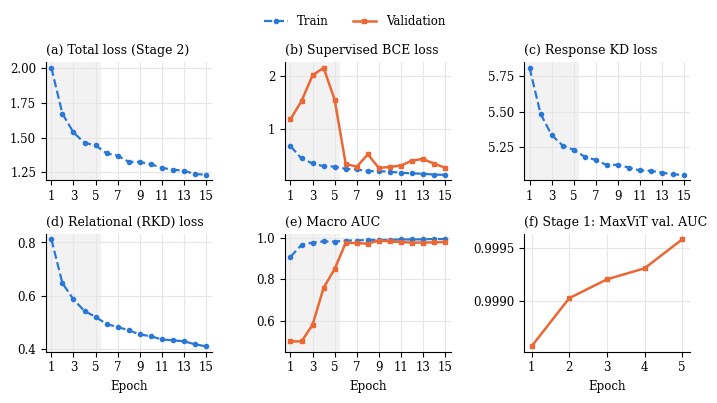

Saved: /content/drive/MyDrive/acne clean pigmentation wrinkles/multistage_camera_ready/fig7_multistage_training_curves.pdf


In [15]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
SAVE_DIR = "/content/drive/MyDrive/acne clean pigmentation wrinkles/multistage_camera_ready"
h = pd.read_csv(os.path.join(SAVE_DIR, "D_multistage_history.csv"))
s = pd.read_csv(os.path.join(SAVE_DIR, "stage1_history.csv"))
e = np.arange(1, len(h) + 1)
plt.rcParams.update({"font.family": "serif", "font.size": 8.5, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e6"})
TR, VA = "#2a78d6", "#eb6834"
fig, ax = plt.subplots(2, 3, figsize=(7.0, 3.9))
def tr(a, k): a.plot(e, h[k], color=TR, lw=1.6, ls="--", marker="o", ms=3, label="Train")
def va(a, k): a.plot(e, h[k], color=VA, lw=1.8, marker="s", ms=3, label="Validation")
for a in ax.flat[:5]:
    a.axvspan(0.5, 5.5, color="#f2f2f2", zorder=0, lw=0); a.set_xticks(range(1, 16, 2)); a.set_xlim(0.5, 15.5)
tr(ax[0,0], "loss");                         ax[0,0].set_title("(a) Total loss (Stage 2)", loc="left", fontsize=9)
tr(ax[0,1], "sup_loss"); va(ax[0,1], "val_sup_loss"); ax[0,1].set_title("(b) Supervised BCE loss", loc="left", fontsize=9)
tr(ax[0,2], "kd_loss");                      ax[0,2].set_title("(c) Response KD loss", loc="left", fontsize=9)
tr(ax[1,0], "rkd_loss");                     ax[1,0].set_title("(d) Relational (RKD) loss", loc="left", fontsize=9)
tr(ax[1,1], "auc"); va(ax[1,1], "val_auc");  ax[1,1].set_ylim(0.45, 1.02); ax[1,1].set_title("(e) Macro AUC", loc="left", fontsize=9)
ax[1,2].plot(s.epoch, s.val_macro_auc, color=VA, lw=1.8, marker="s", ms=3)
ax[1,2].set_xticks(s.epoch); ax[1,2].set_title("(f) Stage 1: MaxViT val. AUC", loc="left", fontsize=9)
for a in ax[1]: a.set_xlabel("Epoch")
hh, ll = ax[0,1].get_legend_handles_labels()
fig.legend(hh, ll, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.03))
plt.tight_layout(rect=(0, 0, 1, 0.96))
out = os.path.join(SAVE_DIR, "fig7_multistage_training_curves.pdf")
plt.savefig(out, bbox_inches="tight"); plt.savefig(out.replace(".pdf", ".png"), dpi=300, bbox_inches="tight")
plt.show(); print("Saved:", out)